# Applied Statistics Assessment

This notebook investigates the Iris dataset using descriptive statistics, correlation, hypothesis testing, and analysis of variance.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.datasets import load_iris

iris = load_iris(as_frame=True)

df = iris.frame
df.columns = [
    "sepal_length",
    "sepal_width",
    "petal_length",
    "petal_width",
    "species_code"
]

df["species"] = df["species_code"].map(
    dict(enumerate(iris.target_names))
)

df.head()

,sepal_length,sepal_width,petal_length,petal_width,species_code,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## Problem 1: Exploring Petal Length

The Iris dataset contains measurements of 150 flowers from three species. This section investigates the distribution of petal length for the complete dataset and for each species.

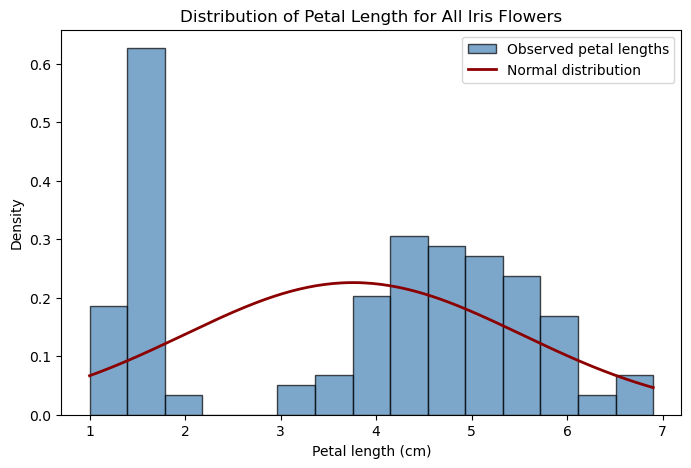

Mean petal length: 3.76 cm
Standard deviation: 1.77 cm


In [2]:
petal_length = df["petal_length"]

mean_petal_length = petal_length.mean()
std_petal_length = petal_length.std()

x = np.linspace(
    petal_length.min(),
    petal_length.max(),
    200
)

plt.figure(figsize=(8, 5))

plt.hist(
    petal_length,
    bins=15,
    density=True,
    alpha=0.7,
    color="steelblue",
    edgecolor="black",
    label="Observed petal lengths"
)

plt.plot(
    x,
    stats.norm.pdf(x, mean_petal_length, std_petal_length),
    color="darkred",
    linewidth=2,
    label="Normal distribution"
)

plt.xlabel("Petal length (cm)")
plt.ylabel("Density")
plt.title("Distribution of Petal Length for All Iris Flowers")
plt.legend()
plt.show()

print(f"Mean petal length: {mean_petal_length:.2f} cm")
print(f"Standard deviation: {std_petal_length:.2f} cm")

Setosa: mean = 1.46 cm, standard deviation = 0.17 cm
Versicolor: mean = 4.26 cm, standard deviation = 0.47 cm
Virginica: mean = 5.55 cm, standard deviation = 0.55 cm


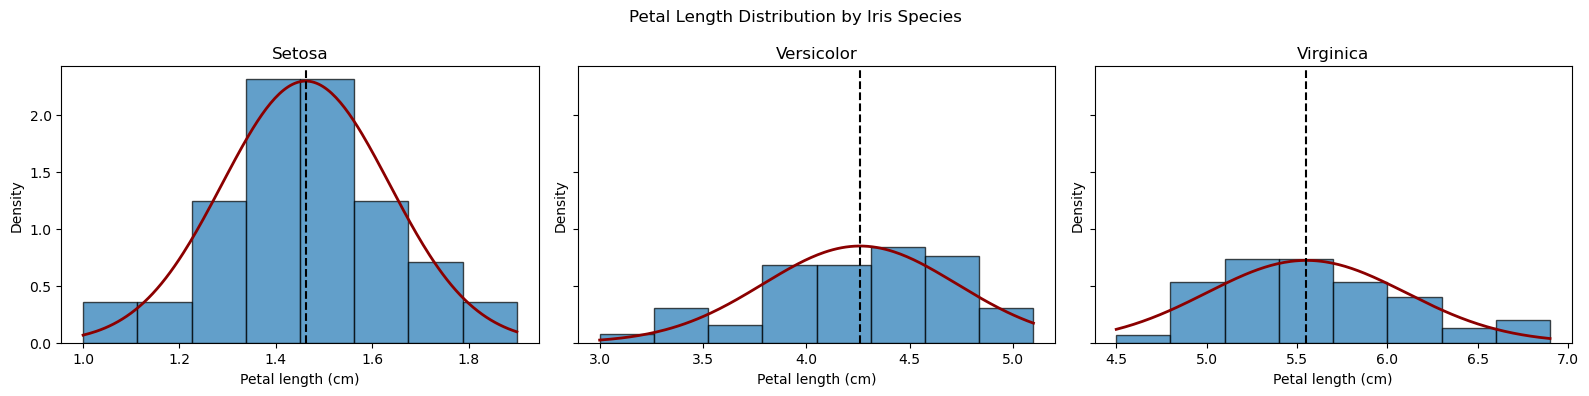

In [3]:
species_order = ["setosa", "versicolor", "virginica"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for ax, species in zip(axes, species_order):
    values = df.loc[df["species"] == species, "petal_length"]
    species_mean = values.mean()
    species_std = values.std()

    x_species = np.linspace(
        values.min(),
        values.max(),
        200
    )

    ax.hist(
        values,
        bins=8,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    ax.plot(
        x_species,
        stats.norm.pdf(x_species, species_mean, species_std),
        color="darkred",
        linewidth=2
    )

    ax.set_title(species.capitalize())
    ax.set_xlabel("Petal length (cm)")
    ax.set_ylabel("Density")
    ax.axvline(species_mean, color="black", linestyle="--")

    print(
        f"{species.capitalize()}: "
        f"mean = {species_mean:.2f} cm, "
        f"standard deviation = {species_std:.2f} cm"
    )

plt.suptitle("Petal Length Distribution by Iris Species")
plt.tight_layout()
plt.show()

### Interpretation

Petal length differs clearly between the three Iris species. Setosa has the smallest average petal length and the lowest variability. Versicolor and virginica have larger average petal lengths, with virginica having the largest mean.

The overall distribution is not well represented by a single normal distribution because it is strongly multimodal. This occurs because the three species have distinctly different petal-length distributions. Within each species, however, the distributions appear approximately unimodal and reasonably close to a normal shape.